# Practical	work	n°4	: Introduction	to	Image	Processing	and	Analysis

### 1. Manual	thresholding

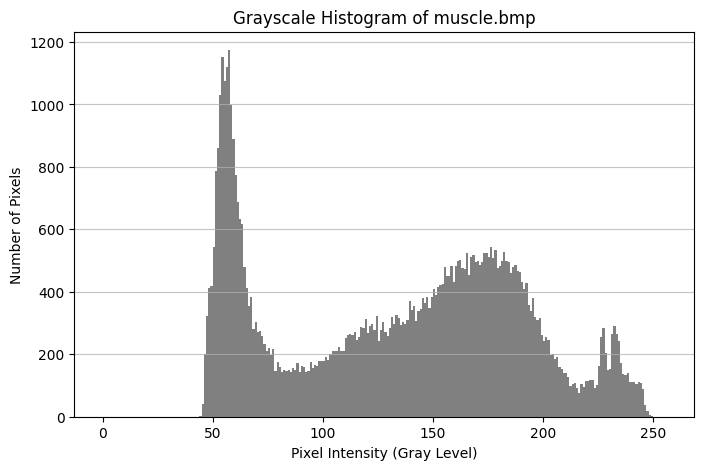

In [48]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('muscle.bmp', cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(8, 5))
plt.hist(img.ravel(), bins=256, range=[0, 256], color='gray')
plt.title('Grayscale Histogram of muscle.bmp')
plt.xlabel('Pixel Intensity (Gray Level)')
plt.ylabel('Number of Pixels')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [49]:
T = 125 

_, segmented_img = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)

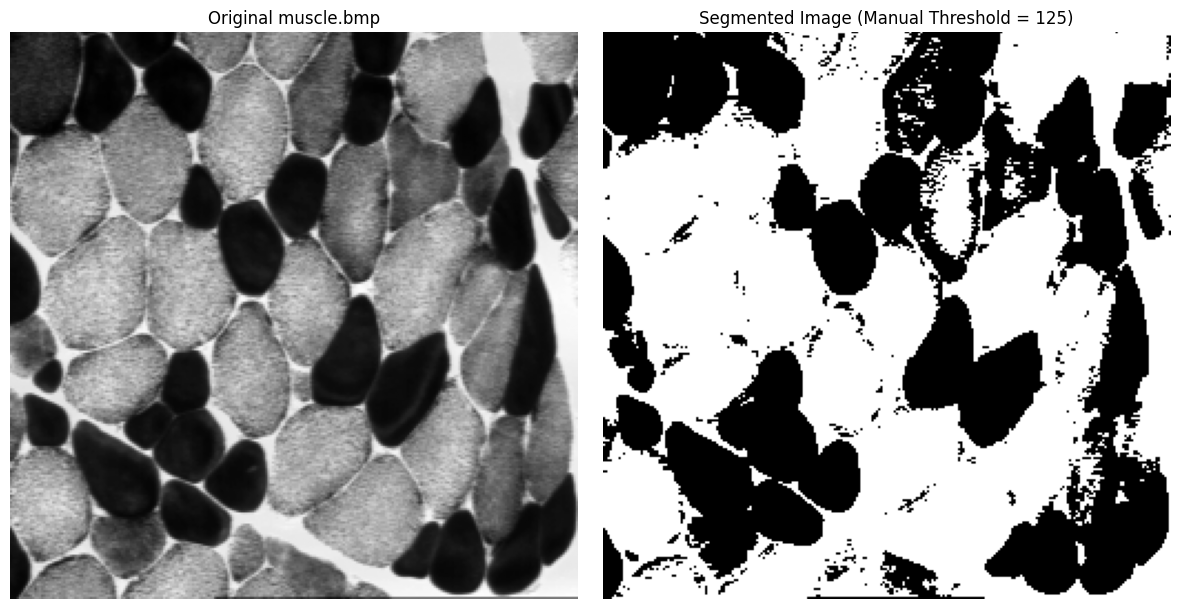

In [52]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original muscle.bmp')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented_img, cmap='gray')
plt.title(f'Segmented Image (Manual Threshold = {T})')
plt.axis('off')

plt.tight_layout()
plt.show()

### 2. Gaussian	thresholding

Gaussian 1 -> A: 1174.0, m: 57, sigma: 5.95


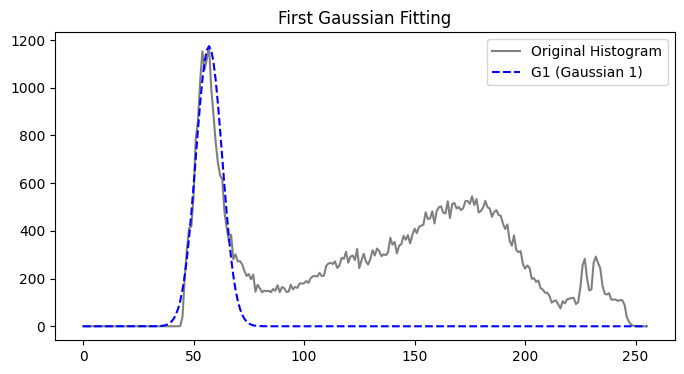

In [54]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math

# Load the image and compute the histogram
img = cv2.imread('muscle.bmp', cv2.IMREAD_GRAYSCALE)
hist = cv2.calcHist([img], [0], None, [256], [0, 256]).flatten()

# 2.2) Function to calculate Gaussian characteristics
def calc_gaussian_params(h):
    # Amplitude (A) is the maximum peak in the histogram
    A = np.max(h)
    
    # Mean (m) is the index (gray level) of that maximum peak
    m = np.argmax(h)
    
    # Find index_half_nv: search backwards from m to find where the value is half of A
    index_half_nv = m
    half_A = A / 2
    for i in range(m, -1, -1):
        if h[i] <= half_A:
            index_half_nv = i
            break
            
    # Calculate sigma using the provided formula
    # sigma = (mean - index_half_nv) / sqrt(2 * log(2))
    sigma = (m - index_half_nv) / math.sqrt(2 * math.log(2))
    
    return A, m, sigma

# 2.3) Determine characteristics of the first Gaussian
A1, m1, sigma1 = calc_gaussian_params(hist)
print(f"Gaussian 1 -> A: {A1}, m: {m1}, sigma: {sigma1:.2f}")

# 2.4) Compute and visualize the Gaussian for gray levels [0 255]
nv = np.arange(256)
# Formula: G(nv) = A * exp(-(nv-m)^2 / (2*sigma^2))
G1 = A1 * np.exp(-((nv - m1)**2) / (2 * (sigma1**2)))

plt.figure(figsize=(8, 4))
plt.plot(nv, hist, label='Original Histogram', color='gray')
plt.plot(nv, G1, label='G1 (Gaussian 1)', color='blue', linestyle='--')
plt.title('First Gaussian Fitting')
plt.legend()
plt.show()

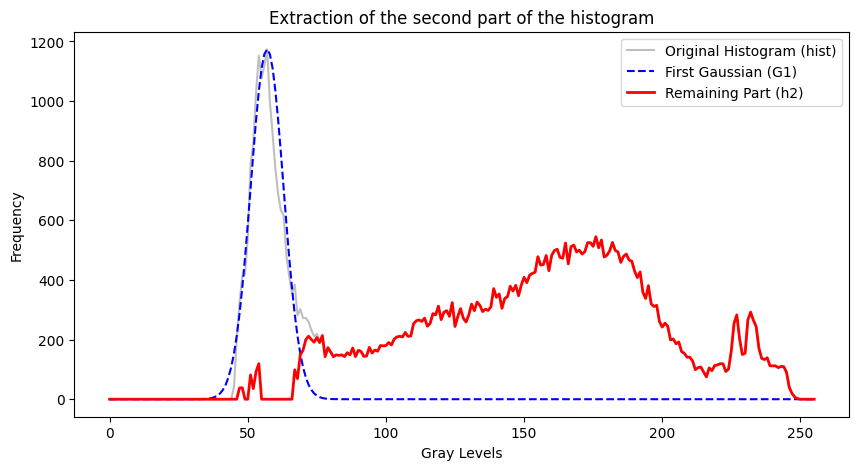

In [56]:
# 2.6) Extract the second part (h2) of the histogram
# We subtract the first Gaussian model from the original histogram
h2 = hist - G1

# Important: After subtraction, some values might become negative 
# (if G1 is slightly higher than the actual histogram). 
# We set those negative values to zero.
h2[h2 < 0] = 0

# Visualization to see the result of the extraction
plt.figure(figsize=(10, 5))
plt.plot(nv, hist, label='Original Histogram (hist)', color='gray', alpha=0.5)
plt.plot(nv, G1, label='First Gaussian (G1)', color='blue', linestyle='--')
plt.plot(nv, h2, label='Remaining Part (h2)', color='red', linewidth=2)

plt.title('Extraction of the second part of the histogram')
plt.xlabel('Gray Levels')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [58]:
# 2.7) Determine the characteristics of the Gaussian associated with h2
A2, m2, sigma2 = calc_gaussian_params(h2)

# Print the extracted parameters for analysis
print("--- Characteristics of the Second Gaussian (G2) ---")
print(f"Amplitude (A2): {A2} (Peak frequency)")
print(f"Mean (m2): {m2} (Dominant gray level of the white cells)")
print(f"Standard Deviation (sigma2): {sigma2:.2f} (Spread of the gray levels)")

--- Characteristics of the Second Gaussian (G2) ---
Amplitude (A2): 545.0 (Peak frequency)
Mean (m2): 176 (Dominant gray level of the white cells)
Standard Deviation (sigma2): 39.92 (Spread of the gray levels)


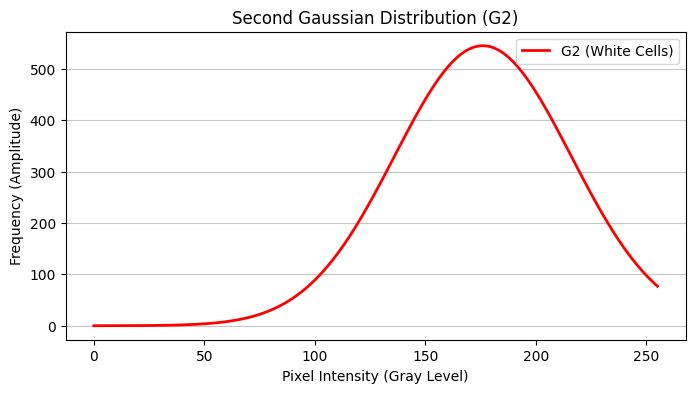

In [60]:
import numpy as np
import matplotlib.pyplot as plt

# Define the gray level interval [0, 255] if you haven't already
nv = np.arange(256)

# 2.8) Compute the second Gaussian G2
# Formula: G2(nv) = A2 * exp(-(nv-m2)^2 / (2*sigma2^2))
G2 = A2 * np.exp(-((nv - m2)**2) / (2 * (sigma2**2)))

# Visualize the isolated second Gaussian
plt.figure(figsize=(8, 4))
plt.plot(nv, G2, label='G2 (White Cells)', color='red', linewidth=2)
plt.title('Second Gaussian Distribution (G2)')
plt.xlabel('Pixel Intensity (Gray Level)')
plt.ylabel('Frequency (Amplitude)')
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

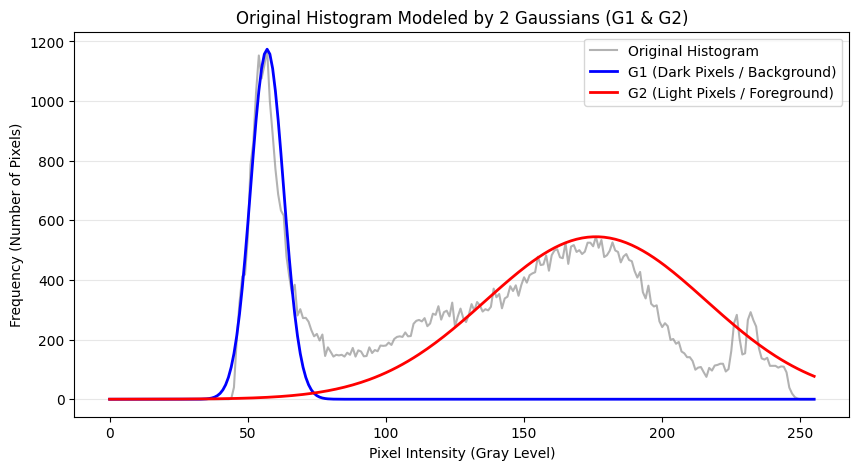

In [62]:
import matplotlib.pyplot as plt

# Create the plot
plt.figure(figsize=(10, 5))

# 1. Plot the original histogram (using .flatten() directly to be absolutely safe!)
plt.plot(nv, hist.flatten(), label='Original Histogram', color='gray', alpha=0.6, linewidth=1.5)

# 2. Plot the first Gaussian (G1 - Black Cells)
plt.plot(nv, G1, label='G1 (Dark Pixels / Background)', color='blue', linewidth=2)

# 3. Plot the second Gaussian (G2 - White Cells)
plt.plot(nv, G2, label='G2 (Light Pixels / Foreground)', color='red', linewidth=2)

# Add labels and formatting
plt.title('Original Histogram Modeled by 2 Gaussians (G1 & G2)')
plt.xlabel('Pixel Intensity (Gray Level)')
plt.ylabel('Frequency (Number of Pixels)')
plt.legend()
plt.grid(axis='y', alpha=0.3)

# Display the graph
plt.show()

In [64]:
import numpy as np

def Gaussian_thresholding(histogram):
    """
    Calculates the optimal threshold by modeling the histogram with two Gaussians
    and finding their intersection point.
    """
    # 1. Ensure the histogram is a 1D array to avoid broadcasting errors
    h = histogram.flatten()
    nv = np.arange(256)
    
    # 2. Calculate the first Gaussian (G1 - Dark pixels)
    A1, m1, sig1 = calc_gaussian_params(h)
    G1 = A1 * np.exp(-((nv - m1)**2) / (2 * (sig1**2)))
    
    # 3. Extract the second part and calculate the second Gaussian (G2 - Light pixels)
    h2 = np.maximum(h - G1, 0)
    A2, m2, sig2 = calc_gaussian_params(h2)
    G2 = A2 * np.exp(-((nv - m2)**2) / (2 * (sig2**2)))
    
    # 4. Define the search interval strictly between the two peaks
    start_search = min(m1, m2)
    end_search = max(m1, m2)
    
    # 5. Find the intersection point (minimum difference between G1 and G2)
    optimal_threshold = start_search
    min_diff = float('inf')
    
    for i in range(start_search, end_search):
        diff = abs(G1[i] - G2[i])
        if diff < min_diff:
            min_diff = diff
            optimal_threshold = i
            
    return optimal_threshold

In [66]:
# Calculate the automatic threshold
auto_T = Gaussian_thresholding(hist)
print(f"The automatically calculated optimal threshold is: {auto_T}")

The automatically calculated optimal threshold is: 74


Automatically calculated optimal threshold: 74


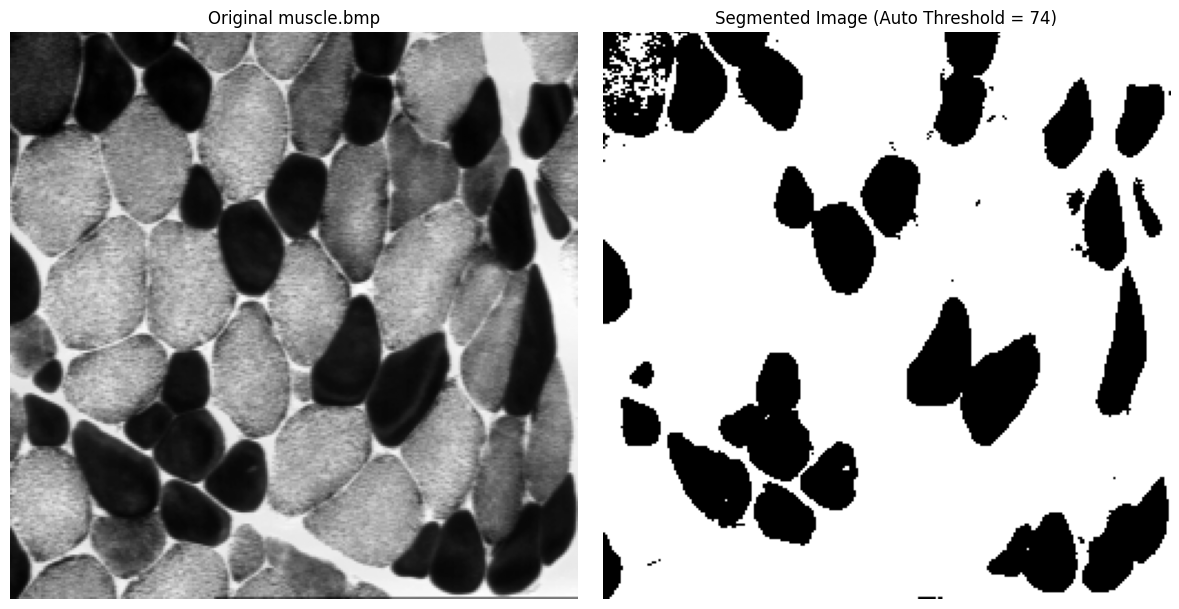

In [68]:
import cv2
import matplotlib.pyplot as plt

# 1. Calculate the automatic threshold using the function from 2.11
auto_T = Gaussian_thresholding(hist)
print(f"Automatically calculated optimal threshold: {auto_T}")

# 2. Apply the threshold to the original grayscale image
# Pixels with intensity > auto_T become 255 (white)
# Pixels with intensity <= auto_T become 0 (black)
_, auto_segmented_img = cv2.threshold(img, auto_T, 255, cv2.THRESH_BINARY)

# 3. Visualize the original image and the segmented result
plt.figure(figsize=(12, 6))

# Original Image
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original muscle.bmp')
plt.axis('off')

# Segmented Image
plt.subplot(1, 2, 2)
plt.imshow(auto_segmented_img, cmap='gray')
plt.title(f'Segmented Image (Auto Threshold = {auto_T})')
plt.axis('off')

plt.tight_layout()
plt.show()

### 3. Color Image thresholding

In [70]:
import cv2

# 3.1) Load the 2CV.tif image
# OpenCV loads color images by default in BGR (Blue, Green, Red) format
img_color = cv2.imread('2CV.tif')

# Check its shape attribute
print(f"The shape of the 2CV image is: {img_color.shape}")

The shape of the 2CV image is: (400, 600, 3)


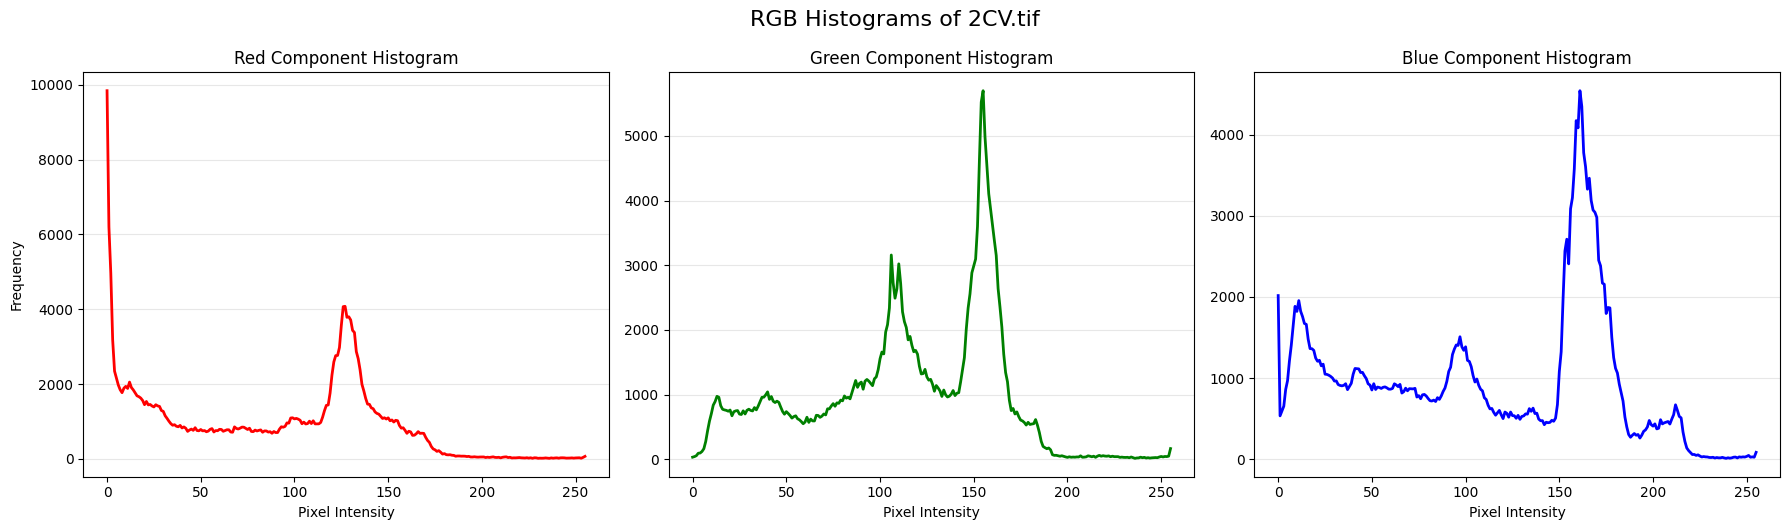

In [72]:
import cv2
import matplotlib.pyplot as plt

# Assuming img_color is already loaded from step 3.1
# img_color = cv2.imread('2CV.tif')

# Compute the histogram for each color channel
# [0] = Blue, [1] = Green, [2] = Red
hist_b = cv2.calcHist([img_color], [0], None, [256], [0, 256])
hist_g = cv2.calcHist([img_color], [1], None, [256], [0, 256])
hist_r = cv2.calcHist([img_color], [2], None, [256], [0, 256])

# Set up the figure to display them side-by-side (1 row, 3 columns)
plt.figure(figsize=(18, 5))

# Subplot 1: Red Component
plt.subplot(1, 3, 1)
plt.plot(hist_r, color='red', linewidth=2)
plt.title('Red Component Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)

# Subplot 2: Green Component
plt.subplot(1, 3, 2)
plt.plot(hist_g, color='green', linewidth=2)
plt.title('Green Component Histogram')
plt.xlabel('Pixel Intensity')
plt.grid(axis='y', alpha=0.3)

# Subplot 3: Blue Component
plt.subplot(1, 3, 3)
plt.plot(hist_b, color='blue', linewidth=2)
plt.title('Blue Component Histogram')
plt.xlabel('Pixel Intensity')
plt.grid(axis='y', alpha=0.3)

# Adjust layout to prevent overlap and display the figure
plt.tight_layout()
plt.suptitle('RGB Histograms of 2CV.tif', fontsize=16, y=1.05)
plt.show()

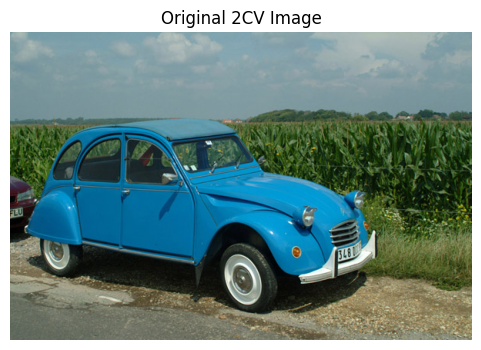

In [75]:
import cv2
import matplotlib.pyplot as plt

# Convert BGR to RGB for correct color display in Matplotlib
img_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 4))
plt.imshow(img_rgb)
plt.title('Original 2CV Image')
plt.axis('off')
plt.show()

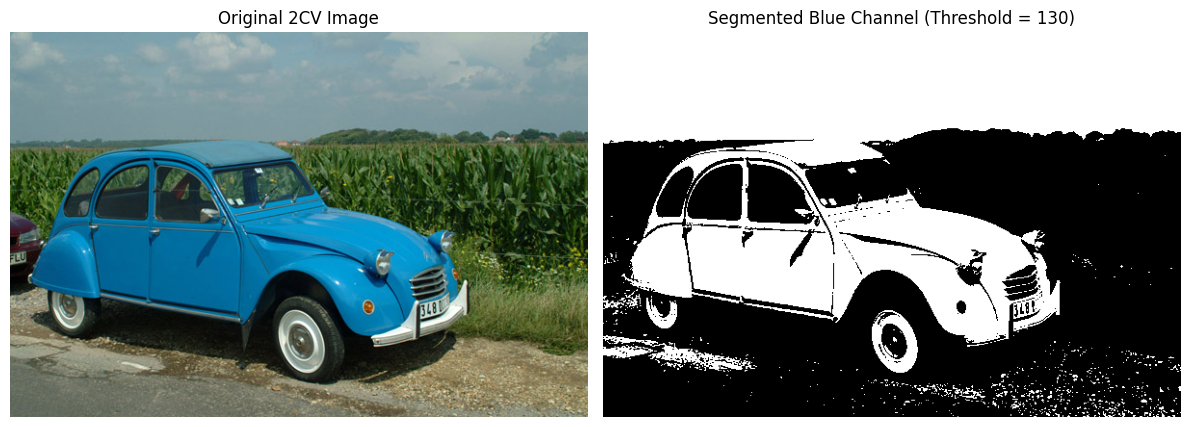

In [77]:
import cv2
import matplotlib.pyplot as plt

# 1. Extract the Blue channel from the original BGR image
blue_channel = img_color[:, :, 0]

# 2. Set your visually selected threshold 
# (Adjust this number based on your specific Blue channel histogram!)
threshold_value = 130

# 3. Apply the threshold
# Pixels with an intensity > threshold_value become 255 (white)
# Pixels with an intensity <= threshold_value become 0 (black)
_, binary_blue = cv2.threshold(blue_channel, threshold_value, 255, cv2.THRESH_BINARY)

# 4. Visualize the original image and the new binary image side-by-side
plt.figure(figsize=(12, 6))

# Original Image (Converted to RGB so Matplotlib displays colors correctly)
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.title('Original 2CV Image')
plt.axis('off')

# Segmented Binary Image
plt.subplot(1, 2, 2)
plt.imshow(binary_blue, cmap='gray')
plt.title(f'Segmented Blue Channel (Threshold = {threshold_value})')
plt.axis('off')

plt.tight_layout()
plt.show()

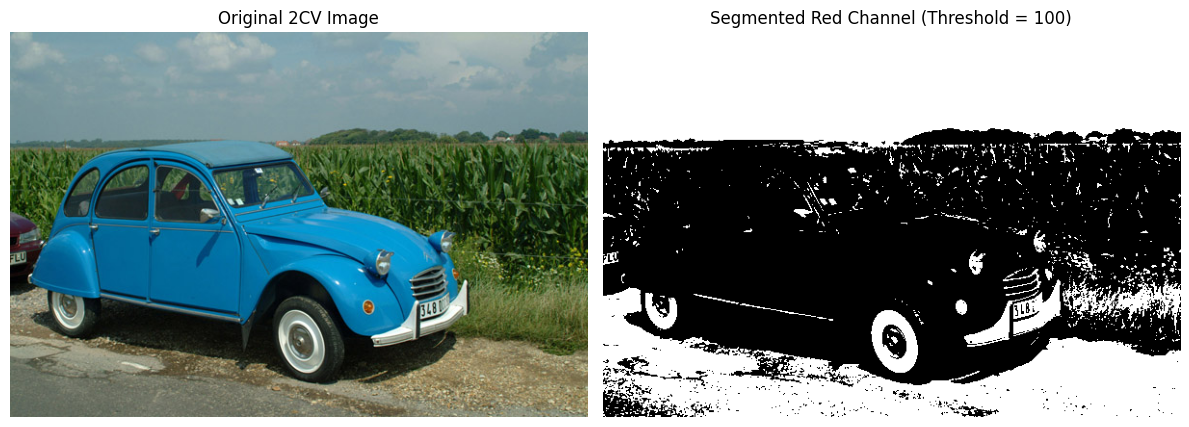

In [79]:
import cv2
import matplotlib.pyplot as plt

# 1. Extract the Red channel from the original BGR image (index 2)
red_channel = img_color[:, :, 2]

# 2. Set a threshold value (you can adjust this based on your red histogram)
T_red = 100

# 3. Apply the threshold
# Pixels with an intensity > T_red become 255 (white)
# Pixels with an intensity <= T_red become 0 (black)
_, binary_red = cv2.threshold(red_channel, T_red, 255, cv2.THRESH_BINARY)

# 4. Visualize the original image and the red channel binary image
plt.figure(figsize=(12, 6))

# Original Image
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.title('Original 2CV Image')
plt.axis('off')

# Segmented Red Channel
plt.subplot(1, 2, 2)
plt.imshow(binary_red, cmap='gray')
plt.title(f'Segmented Red Channel (Threshold = {T_red})')
plt.axis('off')

plt.tight_layout()
plt.show()

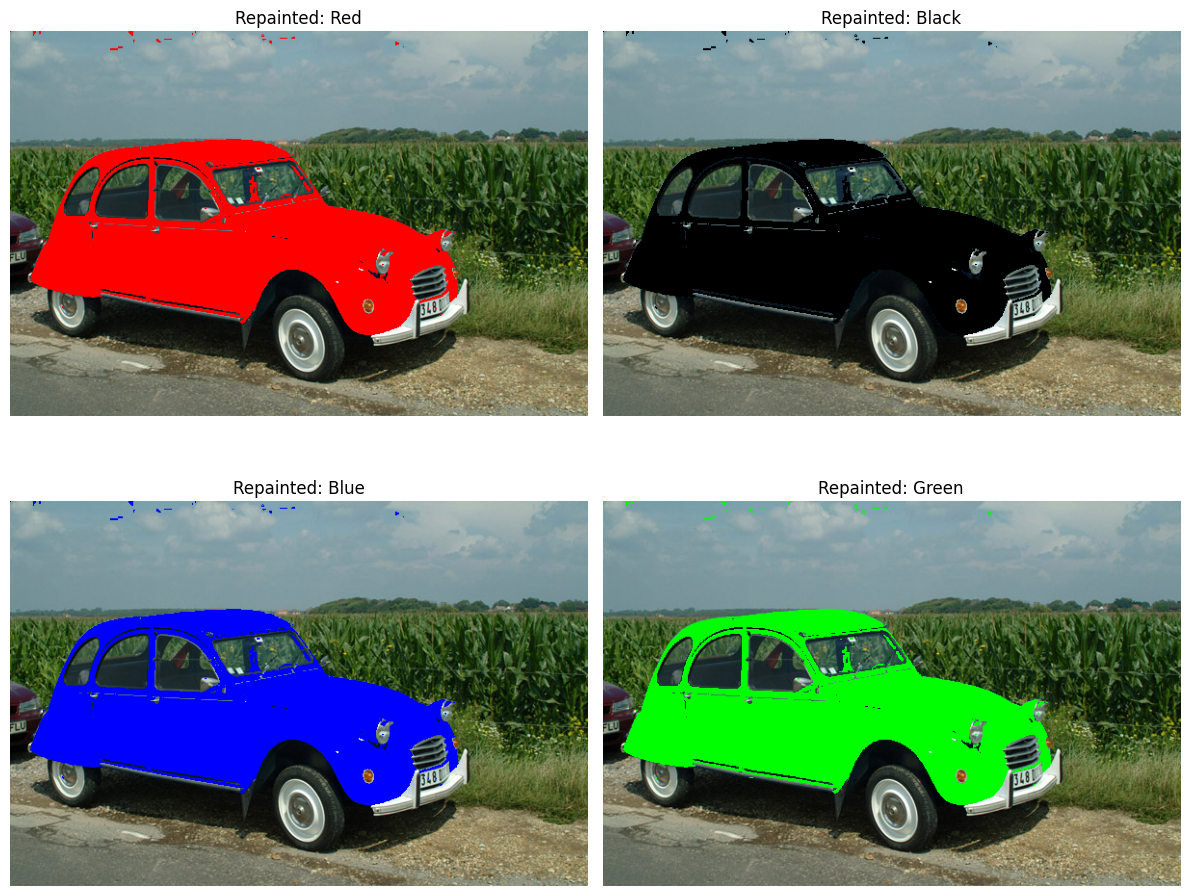

In [83]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- Quick recalculation of the mask from 3.8 to ensure it exists ---
blue_channel = img_color[:, :, 0]
red_channel = img_color[:, :, 2]
blue_minus_red = cv2.subtract(blue_channel, red_channel)
_, final_car_mask = cv2.threshold(blue_minus_red, 50, 255, cv2.THRESH_BINARY)
# --------------------------------------------------------------------

# Define our target colors in BGR format
colors = {
    'Red': (0, 0, 255),
    'Black': (0, 0, 0),
    'Blue': (255, 0, 0),    
    'Green': (0, 255, 0)
}

plt.figure(figsize=(12, 10))

# Loop through our dictionary to generate all 4 variations
for i, (color_name, bgr_value) in enumerate(colors.items(), 1):
    # 1. Create a fresh copy of the original image for each color
    recolored_img = img_color.copy()
    
    # 2. Paint it! Where the mask is white (>0), set the pixel to the new BGR value
    recolored_img[final_car_mask > 0] = bgr_value
    
    # 3. Convert back to RGB so Matplotlib displays it correctly
    recolored_img_rgb = cv2.cvtColor(recolored_img, cv2.COLOR_BGR2RGB)
    
    # 4. Display in a 2x2 grid
    plt.subplot(2, 2, i)
    plt.imshow(recolored_img_rgb)
    plt.title(f'Repainted: {color_name}')
    plt.axis('off')

plt.tight_layout()
plt.show()